In [17]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [19]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam (1).csv


In [20]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [21]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


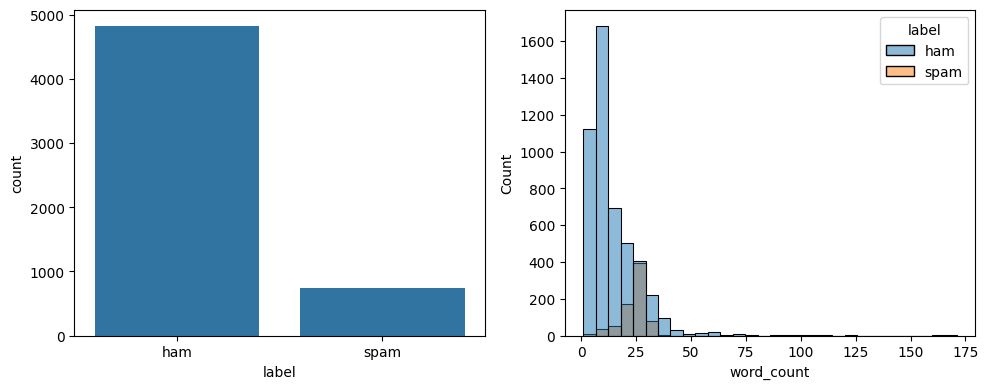

In [22]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()

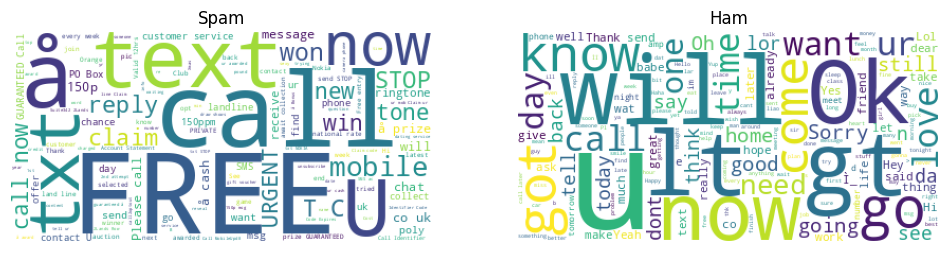

In [23]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()

In [24]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words,
    # remove stopwords,
    # and convert each word to its base (lemma) form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


In [25]:
def extract_features(texts):
    """Return a DataFrame of handcrafted numeric features for a Series/list of raw SMS texts."""
    s = pd.Series(list(texts)).astype(str)
    letters = s.str.count(r'[A-Za-z]').replace(0, 1)   # avoid division by zero
    feats = pd.DataFrame({
        'char_len':        s.str.len(),
        'word_cnt':        s.str.split().str.len(),
        'digit_cnt':       s.str.count(r'\d'),
        'upper_ratio':     s.str.count(r'[A-Z]') / letters,
        'allcaps_words':   s.str.count(r'\b[A-Z]{2,}\b'),
        'exclaim_cnt':     s.str.count('!'),
        'question_cnt':    s.str.count(r'\?'),
        'currency_cnt':    s.str.count(r'[$£€]'),
        'has_url':         s.str.contains(r'http\S+|www\.\S+', case=False, regex=True).astype(int),
        'has_phone':       s.str.contains(r'\d{5,}', regex=True).astype(int),   # long digit runs (phone / short codes)
        'avg_word_len':    s.str.len() / s.str.split().str.len().replace(0, 1),
    })
    if isinstance(texts, pd.Series):
        feats.index = texts.index          # keep original row index so concat with df lines up
    return feats

num_cols = list(extract_features(['sample']).columns)

feat_df = extract_features(df['message'])
df = pd.concat([df.drop(columns=[c for c in num_cols if c in df.columns]), feat_df], axis=1)

# Compare average feature values for ham vs spam
df.groupby('label')[num_cols].mean().T.round(2)

label,0,1
char_len,70.46,137.89
word_cnt,14.13,23.68
digit_cnt,0.29,15.45
upper_ratio,0.08,0.17
allcaps_words,0.38,2.00
exclaim_cnt,0.17,0.69
question_cnt,0.29,0.24
currency_cnt,0.01,0.42
has_url,0.00,0.14
has_phone,0.00,0.77


/tmp/ipykernel_1245/592997021.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['ham', 'spam'])
/tmp/ipykernel_1245/592997021.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['ham', 'spam'])
/tmp/ipykernel_1245/592997021.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['ham', 'spam'])
/tmp/ipykernel_1245/592997021.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['ham', 'spam'])
/tmp/ipykernel_1245/592997021.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['ham',

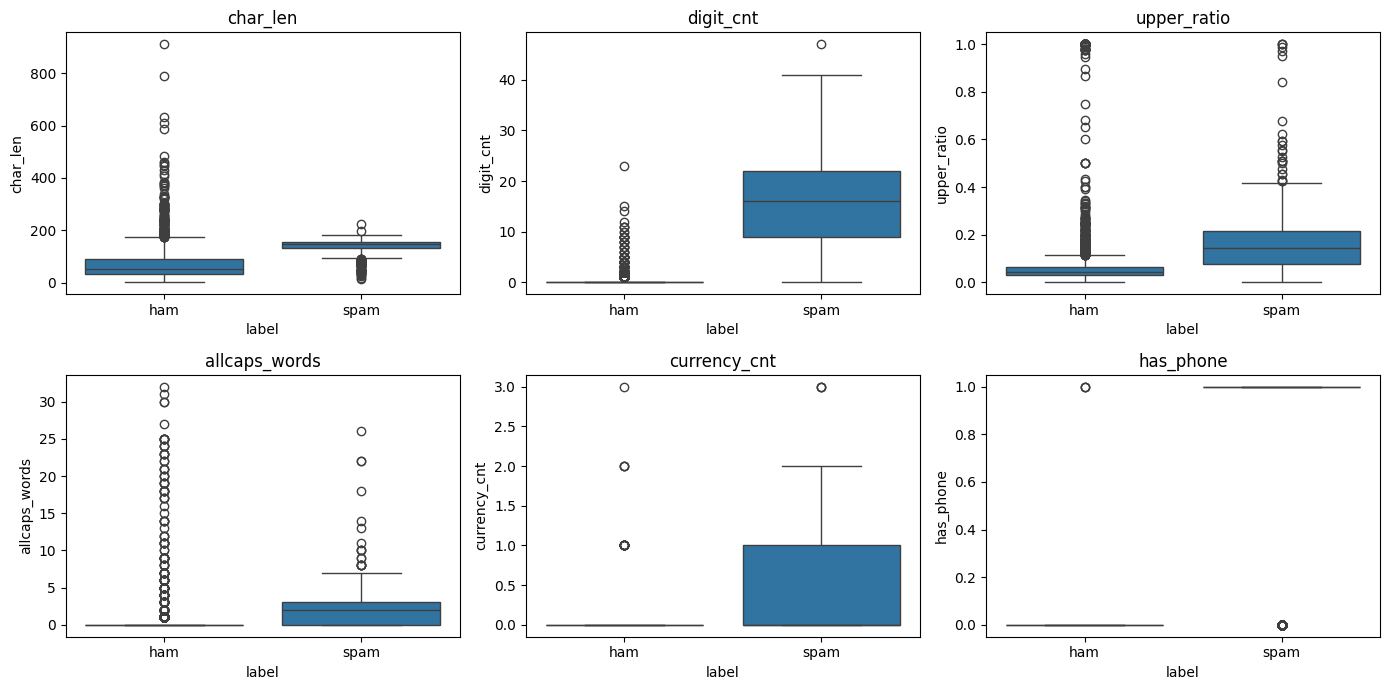

In [26]:
# Visualise how the engineered features differ between ham and spam
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), ['char_len', 'digit_cnt', 'upper_ratio', 'allcaps_words', 'currency_cnt', 'has_phone']):
    sns.boxplot(data=df, x='label', y=col, ax=ax)
    ax.set_xticklabels(['ham', 'spam'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split

# Model input = cleaned text + engineered numeric features
feature_cols = ['clean_message'] + num_cols
X = df[feature_cols]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(4135, 12)
(1034, 12)


In [28]:
# TF-IDF on the text column + scaled engineered features on the numeric columns
preprocessor = ColumnTransformer([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2)), 'clean_message'),
    ('num',   MaxAbsScaler(), num_cols)          # keeps sparsity, scales each feature to [-1, 1]
])

pipeline = Pipeline([
    ('features', preprocessor),
    ('svm', LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))

Accuracy: 0.9864603481624759
Precision: 0.9834710743801653
Recall: 0.9083969465648855
F1: 0.9444444444444444
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       903
           1       0.98      0.91      0.94       131

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



In [29]:
baseline = Pipeline([
    ('features', ColumnTransformer([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2)), 'clean_message')])),
    ('svm', LinearSVC())
]).fit(X_train, y_train)
base_pred = baseline.predict(X_test)

comparison = pd.DataFrame({
    'TF-IDF only':        [accuracy_score(y_test, base_pred), precision_score(y_test, base_pred),
                           recall_score(y_test, base_pred),   f1_score(y_test, base_pred)],
    'TF-IDF + engineered':[accuracy_score(y_test, pred),      precision_score(y_test, pred),
                           recall_score(y_test, pred),        f1_score(y_test, pred)],
}, index=['Accuracy', 'Precision', 'Recall', 'F1']).round(4)
comparison

,TF-IDF only,TF-IDF + engineered
Accuracy,0.9845,0.9865
Precision,0.9832,0.9835
Recall,0.8931,0.9084
F1,0.9360,0.9444


In [30]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)

Best Parameters: {'svm__C': 1}
Best CV Score: 0.9862152357920193


In [31]:
scores=cross_val_score(grid.best_estimator_,df[feature_cols],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())

[0.98646035 0.99129594 0.98259188 0.98646035 0.98354308]
Mean Accuracy: 0.9860703178101378


In [32]:
model=grid.best_estimator_

def predict_sms(text):
    # Build the same inputs used in training: cleaned text + engineered features from the raw text
    row = extract_features([text])
    row['clean_message'] = clean_text(text)
    pred = model.predict(row[feature_cols])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))
print(predict_sms("URGENT! Call 09061701461 NOW to claim your £1000 PRIZE!!!"))

Ham
Ham
Spam
